# Smog Tomorrow: should tomorrow's PE lesson be outdoors?

**Track:** AI + Climate · **Place:** Almaty, Kazakhstan · **User:** a school PE teacher deciding, the evening before, whether tomorrow's lessons stay outdoors.

Every evening at 18:00 the model forecasts **tomorrow's daytime (08:00–18:00) PM2.5** from today's air and weather measurements, and gives a warning when the air is likely to be above 35 µg/m³. Section 6 asks what a school can do now that the public record of the reference monitor has ended: a second model uses **airport weather only** and forecasts the real tomorrow.

**How to run:** *Runtime → Run all*. It takes about one minute, needs no API key and no GPU. All numbers below were produced by this notebook.

In [1]:
import os, subprocess, sys

REPO, BRANCH = "https://github.com/yk59m2cmhw-hash/c", "claude/sleepy-mendel-te40eu"
if not os.path.exists("src/almaty_air.py"):
    if os.path.exists("../src/almaty_air.py"):      # opened from the notebooks/ folder of a local copy
        os.chdir("..")
    else:                                           # Google Colab or any fresh machine
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO, "smog-tomorrow"], check=True)
        os.chdir("smog-tomorrow")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio", "tabulate"], check=False, capture_output=True)
PINNED = "1.9.1"                                    # scikit-learn version used for the reported numbers
import importlib, importlib.metadata
if importlib.metadata.version("scikit-learn") != PINNED:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"scikit-learn=={PINNED}"], check=False, capture_output=True)
    importlib.invalidate_caches()
sys.path.insert(0, "src")

import io
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import almaty_air as aa, run_experiment, demo, live

def show(fig):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=110, facecolor=fig.get_facecolor()); plt.close(fig)
    display(Image(buf.getvalue()))

import sklearn
print("Ready. scikit-learn", sklearn.__version__, "" if sklearn.__version__ == PINNED else
      f"(the saved outputs used {PINNED}; another version builds slightly different trees, so a few borderline days can move)")

Ready. scikit-learn 1.9.1 


## 1. Data

Everything is public and needs no key. The files are already in `data/raw/`; set `REDOWNLOAD = True` to fetch them again from the original sources (`src/download_data.py`).

| Data | Source | Role |
|---|---|---|
| Hourly PM2.5 from the reference-grade monitor "Almaty-8876" (provider AirNow) | OpenAQ public archive | what we predict, and its recent history |
| Weather reports from Almaty airport (METAR, station UAAA) | Iowa Environmental Mesonet | wind, temperature, pressure, visibility |
| PM2.5 from the CAMS global atmospheric model | Open-Meteo Air Quality API | a comparison only, never a model input |

In [2]:
REDOWNLOAD = False
if REDOWNLOAD:
    subprocess.run([sys.executable, "src/download_data.py", "--only", "openaq", "metar", "cams"], check=True)

pm = aa.load_pm(aa.RAW / "openaq_almaty_8876_pm25_hourly.csv")
metar, cams = aa.load_metar(), aa.load_cams()
print(f"PM2.5 monitor : {len(pm):,} hourly values, {pm.index.min():%Y-%m-%d} .. {pm.index.max():%Y-%m-%d}")
print(f"Airport weather: {len(metar):,} reports,       {metar.index.min():%Y-%m-%d} .. {metar.index.max():%Y-%m-%d}")
print(f"CAMS model     : {len(cams):,} hourly values, {cams.index.min():%Y-%m-%d} .. {cams.index.max():%Y-%m-%d}")
pm.tail(3)

PM2.5 monitor : 34,534 hourly values, 2020-04-09 .. 2025-11-14
Airport weather: 126,509 reports,       2020-01-01 .. 2026-11-15
CAMS model     : 37,536 hourly values, 2022-08-04 .. 2026-11-15


datetime_utc
2025-11-14 13:00:00+05:00    30.0
2025-11-14 14:00:00+05:00    21.0
2025-11-14 15:00:00+05:00    27.0
Name: pm25, dtype: float64

**Cleaning.** Timestamps are converted to Almaty time. A few slightly negative readings (instrument noise near zero) are set to 0. A day counts only if at least 6 of its 10 daytime hours have a reading; days with monitor outages are left out rather than filled in.

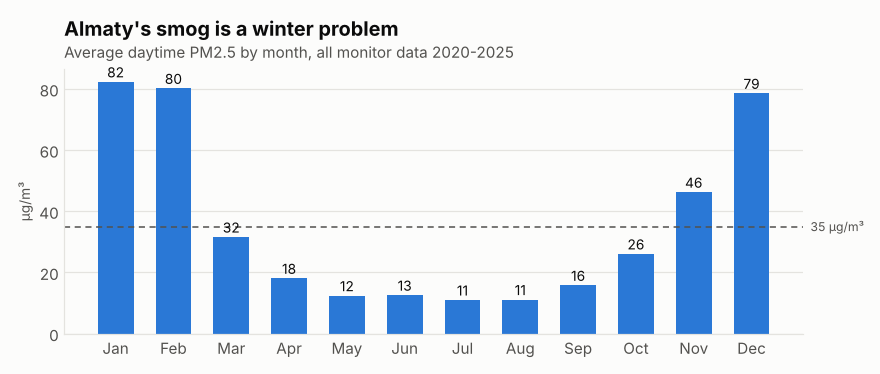

In [3]:
table = aa.build_table(pm, metar, cams)
monthly = table["pm_day"].groupby(table.index.month).mean()
fig, ax = plt.subplots(figsize=(8, 3.4), dpi=110)
bars = ax.bar(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], monthly.values, width=0.62, color=run_experiment.BLUE)
for b, v in zip(bars, monthly.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", fontsize=9, color=run_experiment.INK)
ax.axhline(aa.ALERT_LEVEL, color=run_experiment.MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(1.01, aa.ALERT_LEVEL, "35 µg/m³", transform=ax.get_yaxis_transform(), color=run_experiment.MUTED, fontsize=8, va="center")
ax.set_ylabel("µg/m³", color=run_experiment.MUTED, fontsize=9)
run_experiment.style(ax, "Almaty's smog is a winter problem", "Average daytime PM2.5 by month, all monitor data 2020-2025")
fig.tight_layout(); show(fig)

## 2. The task and the split

One row per evening. **Inputs** (30 numbers) use only what has been measured by 18:00 that day: 9 about PM2.5 (today, last night, last 3 hours, yesterday, the week), 17 about airport weather (wind, temperature, pressure and their change, visibility, rain or snow, fog) and 4 about the calendar of the target day. **Target:** the next day's mean PM2.5 between 08:00 and 18:00.

The days are split **by date, never shuffled**, and this split was fixed before any model was scored on the test period:

In [4]:
parts = aa.split(table)
train, valid, test = parts["train"], parts["valid"], parts["test"]
pd.DataFrame({name: {"days": len(p), "from": p["target_day"].min().date(), "to": p["target_day"].max().date(),
                     "smog days (> 35)": int((p["y"] > aa.ALERT_LEVEL).sum())} for name, p in parts.items()}).T

,days,from,to,smog days (> 35)
train,598,2020-04-11,2023-09-24,178
valid,352,2023-10-01,2024-09-29,86
test,398,2024-10-11,2025-11-14,119


## 3. Baselines and model, on validation data

Settings are chosen here, on the validation year only. The test period is not touched yet.

- **Tomorrow = today** (persistence): the baseline the brief asks for.
- **Average for the month**: what a calendar alone would say.
- **CAMS**: a free global atmospheric model (about 40 km grid). Its archived values come from fresher model runs than a real day-ahead forecast, so this comparison is, if anything, generous to CAMS.
- **Our model**: gradient-boosted decision trees (`HistGradientBoostingRegressor`, depth 2, 300 trees), trained to minimise absolute error.

In [5]:
model_train_only = aa.fit_model(train)
pred_valid = model_train_only.predict(valid[aa.FEATURES])
rows = {
    "Tomorrow = today": aa.mae(valid["y"], valid["persistence"]),
    "Average for the month": aa.mae(valid["y"], aa.climatology(train, valid)),
    "Global model (CAMS)": aa.mae(valid["y"], valid["cams"]),
    "Our model: PM2.5 history + calendar only": aa.mae(valid["y"], aa.fit_model(train, aa.PM_FEATURES + aa.CALENDAR_FEATURES).predict(valid[aa.PM_FEATURES + aa.CALENDAR_FEATURES])),
    "Our model: weather + calendar only (no PM2.5 sensor)": aa.mae(valid["y"], aa.fit_model(train, aa.WEATHER_FEATURES + aa.CALENDAR_FEATURES).predict(valid[aa.WEATHER_FEATURES + aa.CALENDAR_FEATURES])),
    "Our model: all inputs (final)": aa.mae(valid["y"], pred_valid),
}
pd.Series(rows, name="Validation MAE, µg/m³").round(1).to_frame()

,"Validation MAE, µg/m³"
Tomorrow = today,15.1
Average for the month,16.0
Global model (CAMS),15.4
Our model: PM2.5 history + calendar only,12.7
Our model: weather + calendar only (no PM2.5 sensor),11.9
Our model: all inputs (final),11.1


**The improvement we measured:** adding airport weather to the PM2.5 history cut the validation error from 12.7 to 11.1 µg/m³. Weather alone (11.9) is even better than PM2.5 history alone, so the forecast would still work if the monitor went offline.

**The warning threshold.** A missed smog day (children exercise in unhealthy air) is counted as 3 times worse than a false alarm (one lesson moved indoors for nothing). For every method we pick, on validation data, the forecast value above which a warning is given, using this same rule. The cell repeats that tuning. The resulting values (23, 18.5 and 29) were written into the protocol before the test was scored and are fixed in `aa.ALERT_THRESHOLDS`, so every environment evaluates the same rule:

In [6]:
thresholds = {"Tomorrow = today": aa.tune_threshold(valid["y"], valid["persistence"]),
              "Global model (CAMS)": aa.tune_threshold(valid["y"], valid["cams"]),
              "Our model": aa.tune_threshold(valid["y"], pred_valid)}
pd.Series(thresholds, name="warn when the forecast is above, µg/m³").to_frame()

,"warn when the forecast is above, µg/m³"
Tomorrow = today,23.0
Global model (CAMS),18.5
Our model,29.0


## 4. Final test, evaluated once

The model is refitted on train + validation and scored on the test period (Oct 2024 – Nov 2025), which played no part in any choice above. `run_experiment.run()` does this and writes every table and figure to `results/`.

In [7]:
out = run_experiment.run()
t = out["metrics"]["test"]
names = {"persistence": "Tomorrow = today", "seasonal": "Average for the month", "cams": "Global model (CAMS)",
         "linear": "Linear model (ridge)", "model": "Our model (boosted trees)",
         "sensor_free": "Sensor-free model (weather only; added later, see section 6)"}
summary = pd.DataFrame({names[k]: {
    "MAE, µg/m³": round(m["mae"], 1),
    "vs persistence": "-" if k == "persistence" else f"{m['mae_gain_vs_persistence_pct']:+.0f}%",
    "smog days caught": f"{m['alerts_tuned']['caught']} / {m['alerts_tuned']['bad_days']}",
    "missed": m["alerts_tuned"]["missed"], "false alarms": m["alerts_tuned"]["false_alarms"],
    "cost (3 x missed + false alarms)": 3 * m["alerts_tuned"]["missed"] + m["alerts_tuned"]["false_alarms"]} for k, m in t["methods"].items()}).T
print(f"Test period: {t['first_day']} .. {t['last_day']}, {t['n_days']} days, {t['bad_days']} smog days")
summary

Test period: 2024-10-11 .. 2025-11-14, 398 days, 119 smog days


,"MAE, µg/m³",vs persistence,smog days caught,missed,false alarms,cost (3 x missed + false alarms)
Tomorrow = today,15.3,-,108 / 119,11,76,109
Average for the month,15.6,-2%,103 / 119,16,62,110
Global model (CAMS),16.6,-9%,110 / 119,9,83,110
Linear model (ridge),13.1,+14%,98 / 119,21,45,108
Our model (boosted trees),12.3,+20%,103 / 119,16,52,100
"Sensor-free model (weather only; added later, see section 6)",13.2,+14%,100 / 119,19,40,97


In [8]:
print("Does the warning result depend on the threshold? Fewest false alarms each method can reach while missing at most N smog days,")
print("when its threshold is swept on the test days (a descriptive check, added after the test was scored):")
pd.DataFrame(out["matched"]).rename(columns={"persistence": "Tomorrow = today", "cams": "Global model (CAMS)", "model": "Our model", "sensor_free": "Sensor-free model"},
                                    index=lambda n: f"missed at most {n}")

Does the warning result depend on the threshold? Fewest false alarms each method can reach while missing at most N smog days,
when its threshold is swept on the test days (a descriptive check, added after the test was scored):


,Tomorrow = today,Global model (CAMS),Our model,Sensor-free model
missed at most 5,122,121,80,71
missed at most 8,87,86,70,66
missed at most 11,76,70,67,54
missed at most 16,59,47,50,47
missed at most 20,50,38,47,38
missed at most 30,38,33,27,27


MAE gain over persistence: 3.0 µg/m³, 95% interval 1.7 .. 4.5 (bootstrap over weeks)
Days when the air crossed 35 µg/m³ between today and tomorrow: 69 (35 arrivals, 34 clearings)
  persistence is wrong on all of them; our model was on the correct side on 36 (19 arrivals, 17 clearings)
The model's 10-90% range contained the measured value on 79% of test days (target 80%)


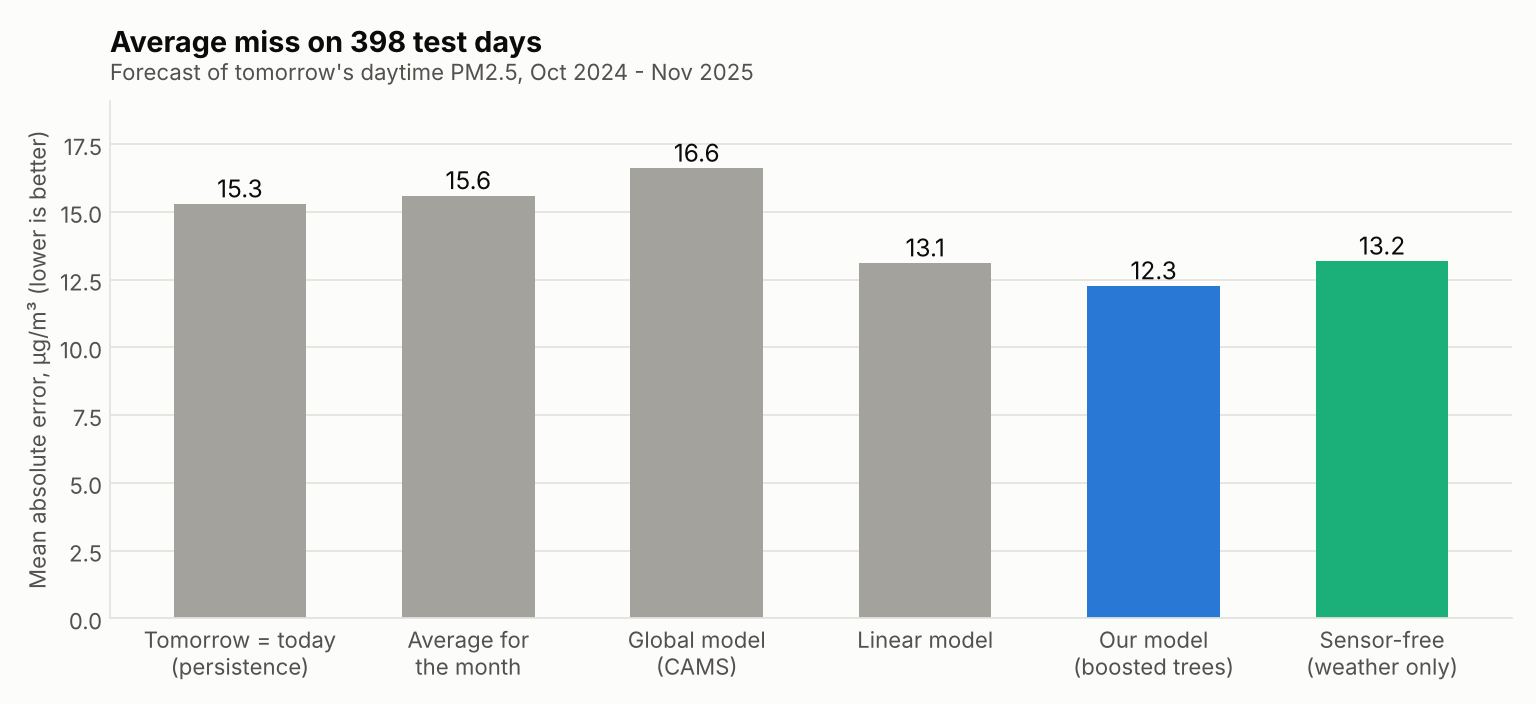

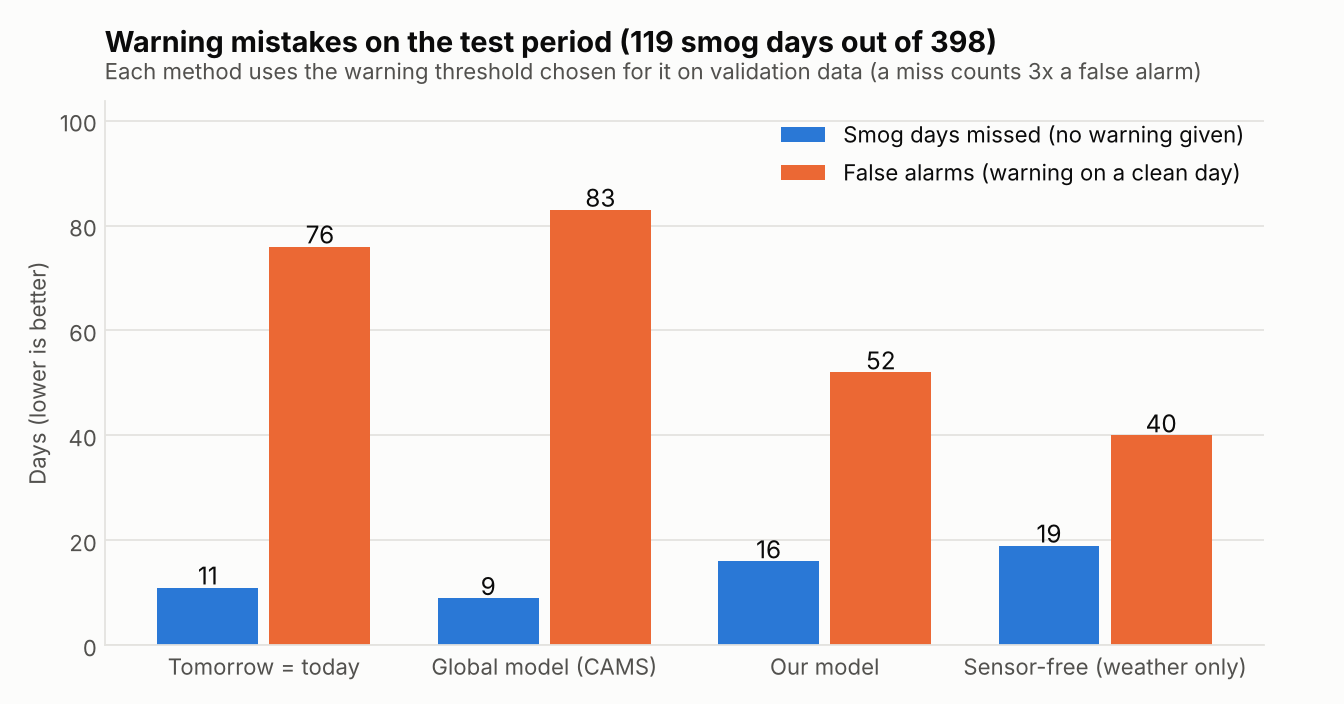

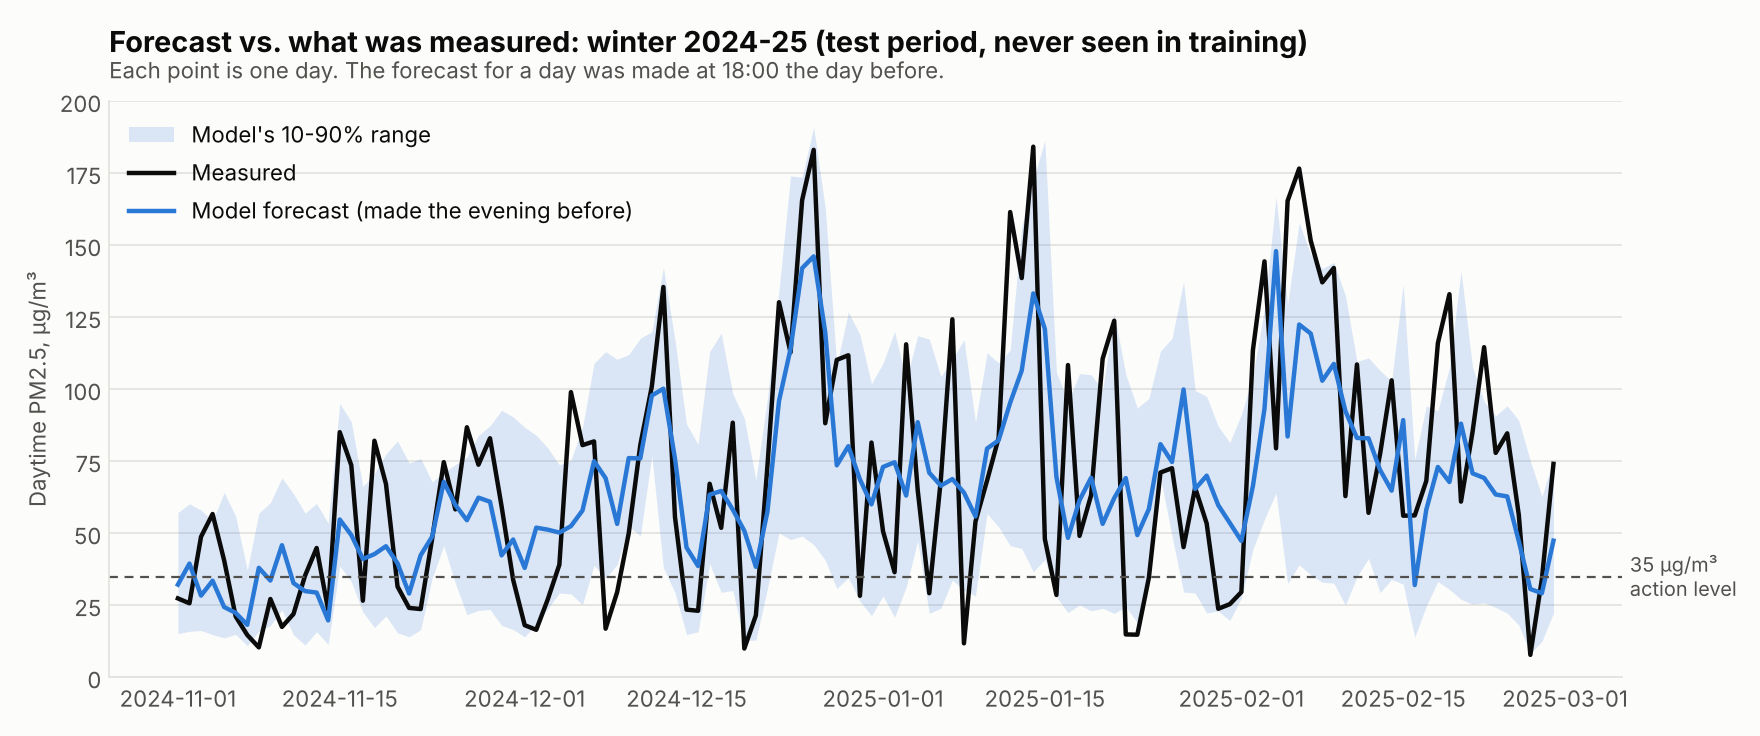

In [9]:
m = t["methods"]["model"]; c = t["change_days"]
print(f"MAE gain over persistence: {t['persistence_mae'] - m['mae']:.1f} µg/m³, 95% interval {m['mae_gain_ci95'][0]:.1f} .. {m['mae_gain_ci95'][1]:.1f} (bootstrap over weeks)")
print(f"Days when the air crossed 35 µg/m³ between today and tomorrow: {c['total']} ({c['smog_arrives']} arrivals, {c['smog_clears']} clearings)")
print(f"  persistence is wrong on all of them; our model was on the correct side on {m['change_days_right_side']['total']} "
      f"({m['change_days_right_side']['smog_arrives']} arrivals, {m['change_days_right_side']['smog_clears']} clearings)")
print(f"The model's 10-90% range contained the measured value on {100 * t['band_10_90_coverage']:.0f}% of test days (target 80%)")
for name in ("fig_mae_by_method.png", "fig_alert_mistakes.png", "fig_forecast_vs_measured.png"):
    display(Image(filename=f"results/{name}", width=820))

**What the numbers say.**
- The model's average miss is 12.3 µg/m³ against 15.3 for "tomorrow = today" (20% lower) and 16.6 for the global model.
- With the warning thresholds chosen on validation, the model raises about a third fewer false alarms than "tomorrow = today" (52 against 76) but **misses more smog days (16 against 11)**. By the 3-to-1 cost rule it is ahead, 100 against 109, which is a modest win.
- The warning counts depend on where the threshold sits. When it is swept, the model raises fewer false alarms than "tomorrow = today" at every number of missed days we checked (67 against 76 at 11 missed). CAMS with a re-tuned threshold comes close to our model at some settings, even though its raw values are far too low: it knows tomorrow's weather and our model does not.
- On the days when the air actually changed sides of the action level, the model is right about half the time. Persistence is right never, by construction.
- A second model that uses no PM2.5 reading at all is scored in section 6.


## 5. Where it fails

In [10]:
print("Largest misses on the test period (the two wind columns and rain/snow are shown for explanation, they are not model inputs):")
display(out["worst_misses"])
by_season = pd.DataFrame({names[k]: m["mae_by_season"] for k, m in t["methods"].items() if k in ("persistence", "cams", "model")}).round(1)
print("MAE by season, µg/m³:"); display(by_season)
print("Which inputs the model relies on most (rise in test MAE when one input is shuffled):"); display(out["importance"].round(2).to_frame("MAE increase, µg/m³"))

Largest misses on the test period (the two wind columns and rain/snow are shown for explanation, they are not model inputs):


,Target day,Today,Forecast,Measured,Error,"Wind today, m/s","Wind on target day, m/s",Rain/snow on target day
2025-02-04,2025-02-05,80.0,84.0,165.0,-82.0,2.1,1.8,no
2025-01-14,2025-01-15,184.0,121.0,48.0,73.0,1.4,1.9,no
2025-02-03,2025-02-04,144.0,148.0,80.0,68.0,1.9,2.1,no
2025-01-11,2025-01-12,83.0,95.0,162.0,-66.0,2.0,1.4,no
2025-02-18,2025-02-19,116.0,68.0,133.0,-65.0,1.8,1.9,no
2025-01-20,2025-01-21,111.0,62.0,124.0,-62.0,1.7,2.3,no
2025-01-16,2025-01-17,29.0,48.0,108.0,-60.0,2.5,1.8,no
2025-01-19,2025-01-20,63.0,53.0,111.0,-57.0,2.3,1.7,no


MAE by season, µg/m³:


,Tomorrow = today,Global model (CAMS),Our model (boosted trees)
heating season (Oct-Mar),23.8,27.1,19.4
warm season (Apr-Sep),5.1,4.0,3.8


Which inputs the model relies on most (rise in test MAE when one input is shuffled):


,"MAE increase, µg/m³"
season_cos,1.94
pm_24h,1.01
temp_min24h,0.85
temp_day,0.81
pressure_day,0.66
pm_evening,0.61
pm_week,0.37
wind_u,0.27


All eight largest misses are in January–February 2025, when daytime PM2.5 doubled or halved overnight (for example 80 → 165, or 184 → 48). Surface wind at the airport was about 2 m/s on both days and there was no rain or snow, so nothing in our inputs announced the change. We think these swings come from the temperature inversion above the city forming or breaking, which a ground station 15 km away cannot see. The model also knows nothing about tomorrow's weather. In the warm season the errors are small (3.8 µg/m³) because the air is almost always clean.

## 6. What if the school has no PM2.5 monitor?

This is not a thought experiment. The public record of the reference monitor we train on **ends on 14 November 2025**. Today's readings from it are not available, so neither our main model nor the baseline "tomorrow = today" can be computed for the real tomorrow.

Section 3 showed, on validation data, that weather and calendar alone already predict well. So we made that a model of its own, the **sensor-free model**: the same boosted trees and settings, but only the 17 airport-weather inputs and 4 calendar inputs.

**Protocol.** Its inputs, settings and warning threshold (36 µg/m³, chosen on validation with the same 3-to-1 rule) were committed to git (`37fb006`) before it was scored on the test period. One caveat: the test period had already been scored once for the main model, so this is a second look at the same days. No choice for the sensor-free model was made using them.

In [11]:
f = t["methods"]["sensor_free"]; p = t["methods"]["persistence"]
compare = pd.DataFrame({
    "Tomorrow = today (needs a monitor)": {"MAE, µg/m³": round(p["mae"], 1), "95% interval of the MAE gain": "-",
        "smog days missed": p["alerts_tuned"]["missed"], "false alarms": p["alerts_tuned"]["false_alarms"],
        "cost (3 x missed + false alarms)": 3 * p["alerts_tuned"]["missed"] + p["alerts_tuned"]["false_alarms"], f"right side on the {c['total']} change days": 0},
    "Our model (needs a monitor)": {"MAE, µg/m³": round(m["mae"], 1), "95% interval of the MAE gain": f"{m['mae_gain_ci95'][0]:.1f} .. {m['mae_gain_ci95'][1]:.1f}",
        "smog days missed": m["alerts_tuned"]["missed"], "false alarms": m["alerts_tuned"]["false_alarms"],
        "cost (3 x missed + false alarms)": 3 * m["alerts_tuned"]["missed"] + m["alerts_tuned"]["false_alarms"], f"right side on the {c['total']} change days": m["change_days_right_side"]["total"]},
    "Sensor-free model (airport weather only)": {"MAE, µg/m³": round(f["mae"], 1), "95% interval of the MAE gain": f"{f['mae_gain_ci95'][0]:.1f} .. {f['mae_gain_ci95'][1]:.1f}",
        "smog days missed": f["alerts_tuned"]["missed"], "false alarms": f["alerts_tuned"]["false_alarms"],
        "cost (3 x missed + false alarms)": 3 * f["alerts_tuned"]["missed"] + f["alerts_tuned"]["false_alarms"], f"right side on the {c['total']} change days": f["change_days_right_side"]["total"]},
}).T
print(f"Test period, {t['n_days']} days, {t['bad_days']} smog days. Sensor-free 10-90% range contained the measured value on {100 * t['sensor_free_band_10_90_coverage']:.0f}% of days.")
compare

Test period, 398 days, 119 smog days. Sensor-free 10-90% range contained the measured value on 75% of days.


,"MAE, µg/m³",95% interval of the MAE gain,smog days missed,false alarms,cost (3 x missed + false alarms),right side on the 69 change days
Tomorrow = today (needs a monitor),15.3,-,11,76,109,0
Our model (needs a monitor),12.3,1.7 .. 4.5,16,52,100,36
Sensor-free model (airport weather only),13.2,0.5 .. 3.7,19,40,97,40


**What this says.** Without any PM2.5 reading, the sensor-free model's average miss is 13.2 µg/m³: worse than our main model (12.3), better than "tomorrow = today" with a monitor (15.3). It misses more smog days than either (19 of 119) and raises the fewest false alarms (40), so by the 3-to-1 rule the three are close: 97, 100 and 109. Knowing today's PM2.5 helps the number, but most of the warning comes from the weather.

**The real tomorrow.** The next cell downloads the latest airport reports and forecasts the next school day. It cannot be checked against the reference monitor, which has no public data for 2026; the table above is our evidence for how far to trust it.

In [12]:
forecast = live.LiveForecaster(table).forecast()      # downloads fresh airport weather; falls back to the saved file without internet
display(Markdown(live.as_text(forecast)))

## Forecast for Monday, 16 November 2026

Made from Almaty airport weather up to 18:00 on 2026-11-15 (21 daytime reports; downloaded now from the Iowa Environmental Mesonet). **No PM2.5 measurement is used.**

### ⚠️ Smog warning: plan PE **indoors**

**Expected daytime PM2.5 (08:00–18:00): about 57 µg/m³**, likely between 25 and 86. A warning is given when the forecast is above 36 µg/m³.

**Why:**
- air pressure today: 1024.3 hPa (typical over the year: 1017.8) pushes the forecast up by about 13 µg/m³
- coldest temperature in the last 24 hours: -2.0 °C (typical over the year: 7.0) pushes the forecast up by about 10 µg/m³
- strongest wind in the last 24 hours: 3.0 m/s (typical over the year: 5.0) pushes the forecast up by about 2 µg/m³

*This forecast cannot be checked against the reference monitor, whose public record ends on 14 Nov 2025. On 398 test days in 2024-25 the same kind of model missed 19 of 119 smog days and raised 40 false alarms. Prototype, not an official warning.*

## 7. Try it

Pick an evening from the test period. The forecast is shown next to what was really measured the next day.

## Forecast for Tuesday, 17 December 2024

Made at 18:00 on 2024-12-16 from that day's air and weather measurements.

### ⚠️ Smog warning: plan PE **indoors** tomorrow

**Expected daytime PM2.5 (08:00–18:00): about 63 µg/m³**, likely between 39 and 113. A warning is given when the forecast is above 29 µg/m³.

**Why:**
- coldest temperature in the last 24 hours: **-10.0 °C** (typical over the year: 7.0) pushes the forecast up by about 14 µg/m³
- air pressure today: **1044.0 hPa** (typical over the year: 1017.5) pushes the forecast up by about 10 µg/m³
- today's daytime temperature: **-7.2 °C** (typical over the year: 16.5) pushes the forecast up by about 10 µg/m³

---

## What actually happened
**Measured: 67 µg/m³.** ✔ The warning was right: the day was above the 35 µg/m³ action level.

“Tomorrow = today” would have said 23 µg/m³ — on the wrong side of the action level.

The sensor-free model (airport weather only, no PM2.5 input) would have said 61 µg/m³: a warning — correct.

*Prototype for one monitor in Almaty. The model cannot see tomorrow's weather, so sudden changes are often missed; on the test period it missed 16 of 119 smog days and raised 52 false alarms.*

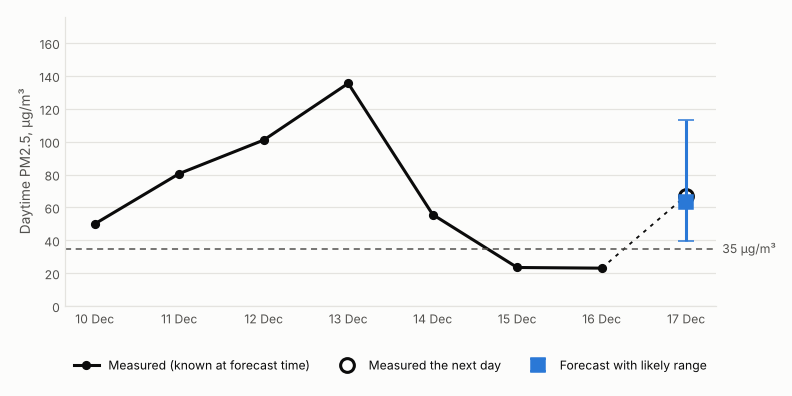

## Forecast for Tuesday, 28 October 2025

Made at 18:00 on 2025-10-27 from that day's air and weather measurements.

### ✅ No warning: PE can stay **outdoors** tomorrow

**Expected daytime PM2.5 (08:00–18:00): about 28 µg/m³**, likely between 15 and 48. A warning is given when the forecast is above 29 µg/m³.

**Why:**
- PM2.5 in the last 3 hours: **47.0 µg/m³** (typical over the year: 17.0) pushes the forecast up by about 4 µg/m³
- today's daytime PM2.5: **33.1 µg/m³** (typical over the year: 16.4) pushes the forecast up by about 3 µg/m³
- average PM2.5 this week: **39.7 µg/m³** (typical over the year: 18.6) pushes the forecast up by about 2 µg/m³

---

## What actually happened
**Measured: 69 µg/m³.** ✘ Missed smog day: no warning was given, but the day was above the action level.

“Tomorrow = today” would have said 33 µg/m³ — on the wrong side of the action level.

The sensor-free model (airport weather only, no PM2.5 input) would have said 25 µg/m³: no warning — wrong.

*Prototype for one monitor in Almaty. The model cannot see tomorrow's weather, so sudden changes are often missed; on the test period it missed 16 of 119 smog days and raised 52 false alarms.*

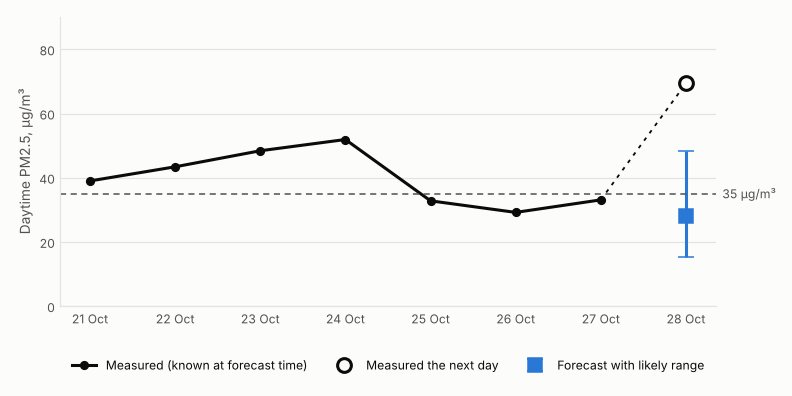

In [13]:
fc = demo.Forecaster()
for evening in ("2024-12-16", "2025-10-27"):       # a caught smog arrival, then a missed smog day
    text, fig = fc.forecast(evening)
    display(Markdown(text)); show(fig)

In [14]:
# Interactive page (text box, button, examples). In Google Colab this opens a public link.
if "google.colab" in sys.modules:
    demo.build_app(fc).launch(share=True)
else:
    print("Interactive page: run `python app.py` in the repository folder, or open this notebook in Google Colab and run this cell.")

Interactive page: run `python app.py` in the repository folder, or open this notebook in Google Colab and run this cell.
